In [529]:
from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime

## CFM 101 — Group Assignment 2026
### Robo-Advising Challenge: Two Clients, Two Strategies

**Team Number:** 11 
**Team Member Names (three or four):** three

Enter the names of all participating members below (one name per line):
- Brian
- Vansh
- Jenny 

**Submission:** Friday, November 27, 2026, at 9:00 AM (Eastern), via Dropbox.  
**Submit this completed Jupyter notebook only.**

Your team must construct **both** portfolios from the supplied `Tickers.csv` file:

- **Client A — Growth:** $\$1,000,000$ CAD; seek the highest expected return.
- **Client B — Low Risk:** $\$750,000$ CAD; seek the lowest portfolio volatility.

Both clients require 10–20 eligible stocks, at most 15% in any stock and at most 40% in any sector. Read the full assignment handout for all eligibility, fee, currency, and competition rules. Do not hardcode the selected stocks. Check that tickers are valid. The supplied ticker universe will permit feasible portfolios.

**No generative AI may be used in preparing this assignment.**

## Data preparation and shared functions

Read `Tickers.csv`, check ticker eligibility, retrieve the data needed for your strategies, and create any functions you will reuse for both clients. Use closing prices from **November 27, 2026** for the purchase calculations. All portfolio values and weights must be calculated in CAD, with purchase fees paid from the client budget.

Some global constants

In [530]:
# our group number
group = 11

# dates for filtering / data cleaning
filter_start = "2025-10-01"
filter_end = "2026-10-01"

# dates for historical analysis
period_start = "2023-10-01"
period_end = "2026-10-01"

# dates for competition
buy_start = "2026-11-17" # CHANGE BEFORE SUBMITTING,
day_after = "2026-11-18" # CHANGE BEFORE SUBMITTING,

# set budgets
budget_A = 1000000
budget_B = 750000

# Max weight in any one sector.
sector_limit = 0.40

# Max weight of any single stock
stock_limit = 0.15

# Min and max number of stocks
min_stocks = 10
max_stocks = 20

Functions to create final portfolio dataframes, and save them as csv file, giving back the budget reconciliation and fees too:

In [531]:
# fees is a function that takes in a number of shares
# it returns the fee accumulated for purchasing that number, in USD

def fees(shares):
    return min(2.15, 0.001 * shares)

# make_base_table is a function that takes in a portfolio dictionary (tickers are keys, values are weights) and a budget (client's A or B)
# it returns the base table (containing purchase prices and estimated fees), the total estimated fees, and the USD to CAD rate on purchase date
# this estimated fees is used to compute the remaining amount investable, and then find real fees (which will be slightly less)

def make_base_table(portfolio, budget):
    # get the tickers from the dictionary of target weights
    tickers = list(portfolio.keys())

    # download the adjusted closing prices for the purchase date
    data = yf.download(tickers, start = buy_start, end = day_after, threads=False, auto_adjust=True)["Close"]

    # get CAD value of one USD on purchase date
    usd_to_cad = yf.download("CAD=X", start = buy_start, end = day_after, threads=False, auto_adjust=True)["Close"].iloc[0,0]

    # create a dictionary to store table's values
    table = {
        "Ticker": [], 
        "Price": [], 
        "Currency": [], 
        "Weight": [], 
        "Price CAD": [],
        "Estimated Fees": []
    }

    # loop through each ticker
    for tick in tickers:
        # look up the purchase price and origina trading currency
        price = data.loc[buy_start, tick]
        currency = stock_info.loc[tick, "Currency"]

        # convert USD prices to CAD if needed
        if currency == "USD":
            price_cad = price * usd_to_cad
        else:
            price_cad = price

        # estimate shares using the full budget before deducting fee
        estimated_shares = portfolio[tick] * budget / price_cad
        # convert the estimated fee from USD to CAD, using estimated shares count
        estimated_fees = fees(estimated_shares) * usd_to_cad
        
        # store the current stock and its calculated values / information in the table dict
        table["Ticker"].append(tick)
        table["Price"].append(price)
        table["Currency"].append(currency)
        table["Weight"].append(portfolio[tick])
        table["Price CAD"].append(price_cad)
        table["Estimated Fees"].append(estimated_fees)

    # convert the dict, table, into dataframe
    table = pd.DataFrame(table)

    # return table, total estimated fee, and purchase date exchange rate
    return table, table["Estimated Fees"].sum(), usd_to_cad

In [532]:
# final_table is a function that takes in a portfolio dictionary (tickers are keys, values are weights) and a budget (client's A or B)
# it outputs the csv file for that portfolio, and returns the final table, the actual fees, and the total actual cost
# it calls base_table to get base estimate fees and costs for the portfolio, to calculate actual costs

def final_table(portfolio, budget):

    # create a base table missing some data, but calculating estimated fees
    # store values we need from that base table
    base_table, estimated_fees, usd_to_cad = make_base_table(portfolio, budget)

    tickers = list(portfolio.keys())
        
    table = base_table.copy()

    # reserve estimated fees
    investable = budget - estimated_fees
    # calculate fractional shares
    table["Shares"] = table["Weight"] * investable / table["Price CAD"]
    # calculate each holding value in CAD
    table["Value"] = table["Shares"] * table["Price CAD"]
    # recalculate weights using the invested stock value only
    table["Weight"] = table["Value"] / table["Value"].sum()

    actual_fees = 0

    for i in range(len(tickers)):
        actual_fees += fees(table.loc[i, "Shares"]) * usd_to_cad

    # Drop unneeded columns, and reorder columns
    table = table.drop(columns=["Price CAD", "Estimated Fees"])
    table = table[["Ticker", "Price", "Currency", "Shares", "Value", "Weight"]]

    # Calculate total CAD spent for budget reconciliation
    total_cost = table["Value"].sum() + actual_fees
    
    # Reindex final table
    table.index = range(1, len(table.index) + 1)
    
    # Create dataframe for csv file output
    file_table = table[["Ticker", "Shares"]]

    # Create option based on the budget to store the right kind of filename
    if budget == budget_A:
        option = "A"
    elif budget == budget_B:
        option = "B"

    # export ticker and share count without the df index
    file_table.to_csv(f"Stocks_Group_{group}_{option}.csv", index=False)
    
    return table, actual_fees, total_cost

Function to check that a portfolio is valid (to be run at the very end of portfolio creation):
Your checks must verify: valid/eligible tickers, stock count, maximum individual weight, maximum sector weight, weights summing to 100%, and total purchases plus fees within budget.

In [533]:
# validate_portfolio is a function that takes in a final portfolio dataframe (from final_table), its total fees, total costs, and the budget
# it outputs PASS or FAIL for the protfolio, for each of the checks described above

def validate_portfolio(table, actual_fees, total_cost, budget):

    # extract tickers from the final portfolio
    tickers = table["Ticker"]

    # 1.1 every ticker is valid
    # assume eligibility until a ticker fails
    eligible = True
    
    for tick in tickers:
        t = yf.Ticker(tick)

        # Check if there is data in here (i.e. not a delisted or invalid ticker)
        if t.history(period="5d").empty:
            print(tick, "doesn't exist")
            eligible = False
            break
    
        # 1.2 every ticker is eligible

        # if the ticker is not in stock info's index (filtered list of eligible stocks)
        if tick not in eligible_tickers:
            print(tick, "not eligible")
            eligible = False
            break

    if eligible:
        print("PASS: tickers valid and eligible")
    else:
        print("FAIL: some tickers invalid / ineligible")


    # 2 valid stock count

    # count rows
    count = len(table.index)

    if count >= min_stocks and count <= max_stocks:
        print("PASS: valid stock count")
    else:
        print("FAIL: invalid stock count")

    # 3 and 4, maximum individual weight and weights sum

    weights_ok = True
    weights_sum = 0

    for i in table.index:
        # recalculate each weight from the actual CAD holding value
        weight = table.loc[i, "Value"] / table["Value"].sum()
        weights_sum += weight

        if weight > stock_limit:
            weights_ok = False
            break

    if weights_ok and np.isclose(weights_sum, 1): 
        # we use np.isclose instead in case there are computer rounding errors
        print("PASS: valid weights")
    else:
        print("FAIL: invalid weights")

    # 5 maximum sector weight

    sectors_ok = True
    sector_weights = {}

    # initialize sector weights
    for tick in table["Ticker"].tolist():
        sector_weights[stock_info.loc[tick, "Sector"]] = 0

    for i in table.index:
        sector = stock_info.loc[table.loc[i, "Ticker"], "Sector"]
        sector_weights[sector] += table.loc[i, "Value"] / table["Value"].sum()

    # check each sector total against the sector limit
    for sector in sector_weights:
        if sector_weights[sector] > sector_limit:
            sectors_ok = False
            break

    if sectors_ok:
        print("PASS: valid sector weights")
    else:
        print("FAIL: invalid sector weights")

    # 6 total purchase cost and fees within budget

    if total_cost <= budget:
        print("PASS: purchases within budget")
    else:
        print("FAIL: purchases not within budget")
        
    # show the actual fee and total spending in CAD
    print(f"Actual Fees: ${actual_fees:.2f} CAD")
    print(f"Total Cost: ${total_cost:.2f} CAD")
    

Extracting stocks / Data Cleaning:

In [534]:
# renamed ticker_file
ticker_file = "Tickers.csv"
raw_tickers = pd.read_csv(ticker_file, header=None, names=["Ticker"]) 
tickers = raw_tickers["Ticker"].drop_duplicates().tolist()  
# deletes the repeated tickers

# Note:
# using .get() to avoid keyerror when a field is missing
# move the volume and close to a seperate cells
# add sector info for the 40% sector weight restriction

stock_rows = []

for tick in tickers:
    t = yf.Ticker(tick)
    # get data for market, currency, sector and market cap
    information = t.get_info()

    # Check if there is data in here (i.e. not a delisted or invalid ticker)
    if t.history(period='max').empty:
        print(tick, "doesn't exist")
        continue
    
    # Check if it's a CAD or USD stock traded in CA or US market
    if information.get("market") not in ["ca_market", "us_market"]:
        print(tick, "wrong market")
        continue

    # Check if it's a stock and not something like a bond or index fund
    if information.get("quoteType") != "EQUITY":
        print(tick, "not stock")
        continue

    # check currency
    if information.get("currency") not in ["CAD", "USD"]:
        print(tick, "currency wrong")
        continue

    # check sector info
    if not information.get("sector"):
        print(tick, "sector missing")
        continue

    # save stock info for later processing
    stock_rows.append({
            "Ticker": tick,
            "Currency": information.get("currency"),
            "Sector": information.get("sector"),
            "Market Cap": information.get("marketCap")
        })

stock_info = pd.DataFrame(stock_rows).set_index("Ticker") 
# set ticker as index
listed_tickers = stock_info.index.tolist()
# save the list for filter
display(stock_info.head())

$AGN: possibly delisted; no timezone found


AGN doesn't exist


$BK: possibly delisted; no price data found  (1d 1927-12-22 -> 2026-11-27)


BK doesn't exist


$CELG: possibly delisted; no timezone found


CELG doesn't exist


$MON: possibly delisted; no timezone found


MON doesn't exist


$RTN: possibly delisted; no timezone found


RTN doesn't exist


,Currency,Sector,Market Cap
Ticker,,,
AAPL,USD,Technology,5167353167872
ABBV,USD,Healthcare,520527642624
ABT,USD,Healthcare,187049689088
ACN,USD,Technology,142066450432
AIG,USD,Financial Services,42631229440


In [535]:
# download stock prices, trading volumes and exchange rates
history = yf.download(
    listed_tickers + ["CAD=X"],
    start=period_start,
    end=period_end,
    threads=False,
    auto_adjust=True
)

# download close, volume and foreign exchange info
close_prices = history["Close"][listed_tickers]
# get closing price info
volume_data = history["Volume"][listed_tickers]
# get volume info
cad_per_usd = history["Close"]["CAD=X"].dropna()
# get USD to CAD exchange info

[*********************100%***********************]  36 of 36 completed


In [536]:
# create a seperate volume data for filter
volume_data = volume_data.loc[(volume_data.index >= filter_start) & (volume_data.index < filter_end)]
print(f"volume screening period: {volume_data.index.min()}, {volume_data.index.max()}")

# Note:
# average daily trading volume = total volume traded over a period (volume) / # of trading dasy in the period
# since months with fewer than 18 valid trading days may affect the average daily trading volume
# 1. filter out months with fewer than 18 valid trading days before calculating liquidity
# 2. use only eligible months to calculate liquidity and determine eligible_tickers

eligible_tickers = []
average_volume = {} 

for ticker in listed_tickers:
    volume = volume_data[ticker].dropna()  
    # delete missed value
    # collect daily volumes only from valid months
    volume_days = []

    # group each stock's volume by calendar month
    for month, monthly_volume in volume.groupby(volume.index.to_period("M")): 
        if len(monthly_volume) >= 18:  
            volume_days.extend(monthly_volume)  

    average_volume[ticker] = pd.Series(volume_days).mean()  
    # transfer list to series to calculate average trading volume
    # keep stocks meeting the minimum average daily volume requirment
    if average_volume[ticker] >= 5_000:
        eligible_tickers.append(ticker)

# attach the calculated liquidity stats by ticker
stock_info["Average Daily Volume"] = pd.Series(average_volume)  
print(f"{len(eligible_tickers)} eligible stocks.")

display(stock_info["Average Daily Volume"].head())

volume screening period: 2025-10-01 00:00:00, 2026-09-30 00:00:00
35 eligible stocks.


Ticker
AAPL    4.828203e+07
ABBV    6.281745e+06
ABT     1.008423e+07
ACN     6.116120e+06
AIG     4.324195e+06
Name: Average Daily Volume, dtype: float64

In [537]:
# tomake sure all stocks are using the same currency

# convert prices to CAD
cad_prices = close_prices[eligible_tickers].copy()
for ticker in eligible_tickers:
    if stock_info.loc[ticker, "Currency"] == "USD":
        # if currency is USD, then change to CAD
        cad_prices[ticker] = cad_prices[ticker] * cad_per_usd
        # match closing price and exchange rate by date

cad_prices = cad_prices.dropna()  
# delete dates which missing info

In [538]:
# After all filtering, this is the table that contains all the complete data for the full consideration period, and valid stocks
# No CBIL.TO in this

display(cad_prices.head())

Ticker,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,PYPL,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319221,121.325726,393.013051,76.241147,175.725132,195.350702,254.954813,33.728010,6.02,...,78.610931,141.522611,73.839996,17.100687,70.040115,198.282192,655.916171,257.465521,174.720008,38.394417
2023-10-03,232.456428,180.677288,122.319422,393.376016,75.013726,170.570816,190.994196,258.372658,32.977460,5.98,...,77.500919,141.424380,70.440002,17.204714,69.378136,196.408580,654.323936,260.871020,174.530831,37.721729
2023-10-04,234.716949,181.429996,122.433557,398.388477,76.116896,174.105576,193.537686,255.990027,33.094827,5.86,...,79.408646,141.326139,72.230003,17.756868,69.195213,197.781115,657.373835,259.559025,174.915328,37.691544
2023-10-05,237.011728,181.598898,123.452851,399.757000,77.327376,173.121948,195.441625,256.040701,33.333052,5.20,...,78.130356,141.623504,71.510002,18.100962,69.997528,194.697581,666.297724,258.126533,174.975295,38.550104
2023-10-06,239.833993,182.060504,123.977228,401.894164,78.033783,175.378129,197.848932,256.817403,33.252432,5.15,...,78.304578,142.615900,73.269997,18.044949,70.359032,196.517930,675.474531,259.738313,175.497617,38.430051


## Non Data Filtering Variables and Functions to be Used in Both Portfolios:

In [539]:
# use S&P 500 as the market benchmark
market_history = yf.download("^GSPC", start=period_start, end=period_end, threads=False, auto_adjust=True)["Close"]

# convert the market index series
market_cad = (market_history["^GSPC"] * cad_per_usd).to_frame("Market")

# drop days where mismatch in market exchange and S&P500 availability
market_cad = market_cad.dropna()

# Merge SP500 and valid tickers dataframes, dropping any dates with mismatch in markets
aligned_prices = pd.concat([cad_prices[eligible_tickers], market_cad], axis=1, join="inner").dropna()
# Calculate returns, dropping days (list first day) with no valid calculation
aligned_returns = aligned_prices.pct_change().iloc[1:].dropna()

# Aligned_prices is used for closing price data for all subsequent calculations
display(aligned_prices.head())
# Aligned_returns is used for daily return data for all subsequent calculations
display(aligned_returns.head())

[*********************100%***********************]  1 of 1 completed


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319221,121.325726,393.013051,76.241147,175.725132,195.350702,254.954813,33.728010,6.02,...,141.522611,73.839996,17.100687,70.040115,198.282192,655.916171,257.465521,174.720008,38.394417,5820.932201
2023-10-03,232.456428,180.677288,122.319422,393.376016,75.013726,170.570816,190.994196,258.372658,32.977460,5.98,...,141.424380,70.440002,17.204714,69.378136,196.408580,654.323936,260.871020,174.530831,37.721729,5784.322991
2023-10-04,234.716949,181.429996,122.433557,398.388477,76.116896,174.105576,193.537686,255.990027,33.094827,5.86,...,141.326139,72.230003,17.756868,69.195213,197.781115,657.373835,259.559025,174.915328,37.691544,5845.217719
2023-10-05,237.011728,181.598898,123.452851,399.757000,77.327376,173.121948,195.441625,256.040701,33.333052,5.20,...,141.623504,71.510002,18.100962,69.997528,194.697581,666.297724,258.126533,174.975295,38.550104,5852.541619
2023-10-06,239.833993,182.060504,123.977228,401.894164,78.033783,175.378129,197.848932,256.817403,33.252432,5.15,...,142.615900,73.269997,18.044949,70.359032,196.517930,675.474531,259.738313,175.497617,38.430051,5905.100605


,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,Market
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-03,-0.000270,0.001986,0.008190,0.000924,-0.016099,-0.029332,-0.022301,0.013406,-0.022253,-0.006645,...,-0.000694,-0.046045,0.006083,-0.009451,-0.009449,-0.002427,0.013227,-0.001083,-0.017520,-0.006289
2023-10-04,0.009724,0.004166,0.000933,0.012742,0.014706,0.020723,0.013317,-0.009222,0.003559,-0.020067,...,-0.000695,0.025412,0.032093,-0.002637,0.006988,0.004661,-0.005029,0.002203,-0.000800,0.010528
2023-10-05,0.009777,0.000931,0.008325,0.003435,0.015903,-0.005650,0.009838,0.000198,0.007198,-0.112628,...,0.002104,-0.009968,0.019378,0.011595,-0.015591,0.013575,-0.005519,0.000343,0.022779,0.001253
2023-10-06,0.011908,0.002542,0.004248,0.005346,0.009135,0.013032,0.012317,0.003034,-0.002419,-0.009615,...,0.007007,0.024612,-0.003094,0.005165,0.009350,0.013773,0.006244,0.002985,-0.003114,0.008981
2023-10-10,-0.004110,-0.004790,-0.002180,-0.008722,-0.004251,0.002635,0.001549,0.023386,0.026593,-0.048544,...,0.003644,0.020882,0.005321,0.009023,-0.004969,-0.010211,0.009903,-0.000914,0.013569,0.002304


In [540]:
# z_score is a function that takes a Series of a statistic and whether a higher value is better for ranking stocks
# it returns a Series of each stock's z score, with missing values given the worst z score (depends on whether higher or lower is worse)

def z_score(ser, higher_better):
    # standardize the statistic relative to its mean and std
    z = (ser-ser.mean())/ser.std()
    
    # replace missing values with the worst available z-score
    if higher_better:
        return z.fillna(z.min())
    else:
        return z.fillna(z.max())

In [541]:
# compare_equal_weight is a function that takes a Series (indexes are tickers, values hold weights)
# it constructs the same portfolio but equal weighted, and gives volatiltiy and return % comparisons over our historical sample period

def compare_equal_weight(weights):
    # Equal-weight Comparison
    
    # calculate the price growth factor for each stock
    prices = cad_prices[weights.index] # store our portfolio's stocks into prices Series
    growth = prices.iloc[-1] / prices.iloc[0]
    
    equal_weights = pd.Series(1 / len(weights), index = weights.index)
    
    # calculate cumulative historical returns
    strategy_return = (growth * weights).sum() - 1
    equal_return = (growth * equal_weights).sum() - 1
    
    # calculate daily volatility
    strategy_std = weighted_std(weights, prices)
    equal_std = weighted_std(equal_weights, prices)
    
    # comparison table
    comparison = pd.DataFrame({
        "Historical Return (%)": [100 * strategy_return, 100 * equal_return],
        "Daily Std (%)": [100 * strategy_std, 100 * equal_std],
    }, index=["Optimized Portfolio", "Equal Weight Portfolio"])
    
    display(comparison.round(6))
    
    # produce the differences in percentage points
    print(f"Start Date: {prices.index[0].date()}")
    print(f"End Date: {prices.index[-1].date()}")
    print(f"Dates are inclusive")
    print(f"Daily Std change: {100 * (strategy_std - equal_std):+.4f} percentage points")
    print(f"Historical return change: {100 * (strategy_return - equal_return):+.4f} percentage points")

In [542]:
# count_price_plummets is a function that takes in a period length (in trading days) and a price drop threshold (decimal)
# it divides our historical sample period into small chunks with the given period length
# then it returns a Dataframe containing in how many time each stock dropped by the threshold, in any of those small period chunks (rough tally of short term crash in price)

def count_price_plummets(period, threshold):
    # create a table to store the number of detected declines of each stock
    result = pd.DataFrame()
    for tick in eligible_tickers:
        result.loc[tick, "Occurrences"] = 0
    # start with most recent complete price interval
    interval = [len(cad_prices)-period-1, len(cad_prices)-1]
    while interval[0] >= 0:
        for tick in eligible_tickers:
            # compare the ending price with the threshold times the starting price
            if cad_prices.iloc[interval[1]][tick] <= cad_prices.iloc[interval[0]][tick] * threshold:
                result.loc[tick, "Occurrences"]+=1

        # shift endpoints
        interval[0]-=period
        interval[1]-=period

    return result

In [543]:
# weighted_std is a function that takes in starting portfolio (Series, indexing are tickers, values are weights) and a table of closing prices for each stock
# it returns the std of the daily returns of that buy-and-hold portfolio over our historical sample period

def weighted_std(weights, period_prices): 
        shares = weights / period_prices.iloc[0] 
        values = (period_prices * shares).sum(axis=1)
        returns = values.pct_change().iloc[1:]
        return returns.std(ddof=1)

## CLIENT A - HIGH RETURNS PORTFOLIO:

In [544]:
# make a separate copy of CAD prices for high-return calculations
full_data = cad_prices.copy()

# add the treasury bill ETF for estimating the risk-free return
full_data["CBIL.TO"] = yf.download("CBIL.TO", period_start, period_end, auto_adjust=True)["Close"]

# if days are missing, replace them with the previous day's price
full_data = full_data.ffill()

# show the first few rows to check the data
display(full_data.head())

[*********************100%***********************]  1 of 1 completed


Ticker,AAPL,ABBV,ABT,ACN,AIG,AMZN,AXP,BA,BAC,BB.TO,...,QCOM,SHOP.TO,T.TO,TD.TO,TXN,UNH,UNP,UPS,USB,CBIL.TO
Date,,,,,,,,,,,,,,,,,,,,,
2023-10-02,232.519125,180.319221,121.325726,393.013051,76.241147,175.725132,195.350702,254.954813,33.728010,6.02,...,141.522611,73.839996,17.100687,70.040115,198.282192,655.916171,257.465521,174.720008,38.394417,45.243130
2023-10-03,232.456428,180.677288,122.319422,393.376016,75.013726,170.570816,190.994196,258.372658,32.977460,5.98,...,141.424380,70.440002,17.204714,69.378136,196.408580,654.323936,260.871020,174.530831,37.721729,45.229576
2023-10-04,234.716949,181.429996,122.433557,398.388477,76.116896,174.105576,193.537686,255.990027,33.094827,5.86,...,141.326139,72.230003,17.756868,69.195213,197.781115,657.373835,259.559025,174.915328,37.691544,45.243130
2023-10-05,237.011728,181.598898,123.452851,399.757000,77.327376,173.121948,195.441625,256.040701,33.333052,5.20,...,141.623504,71.510002,18.100962,69.997528,194.697581,666.297724,258.126533,174.975295,38.550104,45.247669
2023-10-06,239.833993,182.060504,123.977228,401.894164,78.033783,175.378129,197.848932,256.817403,33.252432,5.15,...,142.615900,73.269997,18.044949,70.359032,196.517930,675.474531,259.738313,175.497617,38.430051,45.256702


In [545]:
# half life for sharpe calculations is 1 trading year = roughly 252 days
half_life = 252

# since dividend calculation function works in calendar days, adjust half life to be 1 year = 365 calendar days
dividend_half_life = 365

In [546]:
# get_stats is a function that takes in a ticker and a half life
# it returns the half-life weighted mean and std of the stock's daily returns, i.e. older makes less impact on statistic returned

def get_stats(tick, half_life):
    # get available price history for the stock
    s = full_data[tick].dropna()
    # calculate daily logarithmics returns, weighting recent days more using our half life constant
    delta = np.log(1 + s.pct_change()).ewm(halflife = half_life)
    # take the latest weighted std and mean
    standard_deviation = delta.std().iloc[-1]
    average = delta.mean().iloc[-1]

    return average, standard_deviation

Stage 1: Calculating statistics for stocks

In [547]:
# get the risk-free return rate (from the ETF of T-Bills, CBIL.TO)
Rf = get_stats("CBIL.TO", half_life)[0]
print("Risk free return:", Rf)

# create a dict to store sharpe of each stock over sample period
sharpe = {}

# calculate Sharpe ratio for each eligible stock
for tick in eligible_tickers:
    # get the stock's weighted mean return and std
    stats = get_stats(tick, half_life)
    # Sharpe ratio = (mean return - risk-free return) / std
    # this creates a Sharpe ratio that is effectively recency weighted 
    sharpe[tick] = (stats[0] - Rf)/stats[1]

# sort the stocks by Sharpe ratios
sharpe = dict(sorted(sharpe.items(), key = lambda item:item[1]))
print(sharpe)

Risk free return: 0.00011224399848943479
{'T.TO': np.float64(-0.09195382627876429), 'ACN': np.float64(-0.035912000387258745), 'PEP': np.float64(-0.032150652990237595), 'UPS': np.float64(-0.02036302447831426), 'ABT': np.float64(-0.017422255629144616), 'PYPL': np.float64(-0.014259057063614976), 'BA': np.float64(-0.012571458946397447), 'UNH': np.float64(-0.009529173426238985), 'CL': np.float64(0.003895264271575354), 'AIG': np.float64(0.004436264754880115), 'LMT': np.float64(0.008668859722452073), 'AXP': np.float64(0.017961989649817614), 'QCOM': np.float64(0.018528734376238126), 'BLK': np.float64(0.024127758324009936), 'PFE': np.float64(0.025959207468712095), 'BIIB': np.float64(0.027516697594444212), 'AMZN': np.float64(0.027884131120077527), 'SHOP.TO': np.float64(0.029921342062367184), 'UNP': np.float64(0.03103197465100999), 'BMY': np.float64(0.031742584238035824), 'LLY': np.float64(0.040668707880317734), 'TXN': np.float64(0.042284512275364235), 'BAC': np.float64(0.04250233933303765), 'USB

In [548]:
# get_momentum is a function that takes in no parameters
# it returns a Series (indexing of tickers, values of returns) of each stock's returns over 12 months (imagine a 12 month slice of time ending when our historical sample ends, but then shift it back by 1 month) 
# this is a 12-1 momentum calculation 

def get_momentum():
    # use CAD prices of eligible stocks only
    prices = full_data[eligible_tickers]

    # convert the period_end text into datetime object
    end = pd.Timestamp(period_end)
    # subtract 1 month to get end for momentum calculation (skipping last month because of reversal)
    momentum_end = end.replace(month = end.month - 1)
    # take the above and subtract 1 year to get the start for the momentum calculation
    momentum_start = momentum_end.replace(year = momentum_end.year - 1)
    
    # calculate the price return between the two dates
    return (prices.asof(momentum_end)) / (prices.asof(momentum_start)) - 1

In [549]:
# get_dividends is a function that takes in no parameters
# it returns a Series of each stock's half-life weighted dividend yield (dividends paid / price) over our historical sample
def get_dividends():
    # store the weighted dividend yields by ticker
    result = pd.Series()
    for tick in eligible_tickers:
        div = yf.Ticker(tick).dividends
        # match date with price data
        div.index = div.index.tz_localize(None).normalize()

        # keep dividend payments within historical period
        div = div[(div.index >= period_start) & (div.index < period_end)]

        # stocks with 0 dividends get a dividend yield rating of 0
        if div.empty:
            result[tick] = 0
            continue

        # convert USD dividends to CAD
        if stock_info.loc[tick, "Currency"] == "USD":
            div = (div * cad_per_usd.asof(div.index))

        # get the latest available stock price at each dividend date
        price = full_data[tick].asof(div.index)

        # our stat "dividend yield" is calculated as dividend / price
        yields = div/price

        # give older dividend payments less weight
        age = (pd.Timestamp(filter_end) - div.index).days
        weights = 0.5**(age/dividend_half_life)

        # add up the weighted dividend yields
        result[tick] = np.sum(yields*weights)

    return result

In [550]:
# sharpe_check is a function that takes in no parameters
# it returns a Series telling us whether each stock's Sharpe ratio, if it is negative, and 0 if it was positive
# so we can penalize only negative ones
def sharpe_check():
    result = pd.Series()
    for tick in eligible_tickers:
        # keep negative Sharpe ratios and replace positive ones with zero
        result[tick] = min(0, sharpe[tick])

    return result

In [551]:
# revenue_CAGR is a function that takes in no parameters
# it returns a Series of each stock's compound annual growth rate of total revenue (comparing the latest and oldest revenue reporting from our historical sample)
def revenue_CAGR():
    result = pd.Series()
    for tick in eligible_tickers:
        # get the annual income statement for this stock
        stmt = yf.Ticker(tick).income_stmt
        if "Total Revenue" not in stmt.index:
            result[tick] = np.nan
            continue

        # sort the available revenue data from oldest to newest
        rev = stmt.loc["Total Revenue"].dropna().sort_index()

        # need at least two revenue figures to calculate growth
        if len(rev) < 2:
            result[tick] = np.nan
            continue

        # calculate the number of years between the first and last revenue dates
        years = (rev.index[-1] - rev.index[0]).days/365.25
        # calculate annual compounded revenue growth rate
        result[tick] = pow((rev.iloc[-1]/rev.iloc[0]), (1/years)) - 1

    return result

In [552]:
# revenue_std is a function that takes in no paramteres
# it returns a Series of the std of each stock's yearly revenue growth rates (volatility in their revenue growth)
def revenue_std():
    result = pd.Series()
    for tick in eligible_tickers:
        # get annual revenue data
        stmt = yf.Ticker(tick).income_stmt
        if "Total Revenue" not in stmt.index:
            result[tick] = np.nan
            continue
        
        # calculate the percentage change in revenue each year
        rev_delta = stmt.loc["Total Revenue"].dropna().sort_index().pct_change().dropna()

        # determine how much revenue growth varies
        result[tick] = rev_delta.std()
        # pull 3 yearly growth rates for more menaingful std
        if len(rev_delta) <= 2:
            result[tick] = np.nan

    return result

In [553]:
score_df = pd.DataFrame()

# we put True if a higher value of the statistic is better, and False if a lower value is better (decides what the default score given missing data should be)
# eg. dividends should be -ve because higher dividends means less growth
# count price drops of at least 20% within 15 trading day periods of market trading across historical sample
score_df["Drops"] = count_price_plummets(15, 0.8)["Occurrences"]
score_df["Momentum"] = z_score(get_momentum(), True)
score_df["Dividends"] = z_score(get_dividends(), False)
score_df["Sharpe Check"] = z_score(sharpe_check(), True)
score_df["Revenue CAGR"] = z_score(revenue_CAGR(), True)
score_df["Revenue STD"] = z_score(revenue_std(), False)

# note, some things have to be negative because they lower the score (this weight/factor is a multiplier on the z score / occurence rate)
score_weights = {"Drops": -1.5, "Momentum": 1, "Dividends": -0.375, "Sharpe Check": 0.4, "Revenue CAGR": 0.875, "Revenue STD": -0.25}

# multiply each statistic by its assigned weight and add them up for each stock
overall_score = sum(score_df[x] * score_weights[x] for x in score_weights).to_dict()

In [554]:
# sort stocks from highest to lowest growth scores
overall_score = dict(sorted(overall_score.items(), key=lambda x: -x[1]))

overall_score

{'LLY': 4.21043941091956,
 'SHOP.TO': 2.344258368530329,
 'CAT': 2.220447435176191,
 'TD.TO': 1.901152475002466,
 'MRK': 1.7698360054388855,
 'RY.TO': 1.3705514220644155,
 'AAPL': 1.302425118908309,
 'AMZN': 1.0929164003460898,
 'C': 0.7570082831101903,
 'BAC': 0.42822070207038265,
 'AXP': 0.38052721379890436,
 'KO': 0.285415293713476,
 'PM': 0.26911552223541346,
 'BMY': 0.23271365810254768,
 'BLK': 0.016972018184482088,
 'UNP': 0.011859253784284235,
 'USB': -0.012475402014806472,
 'BIIB': -0.23065544827463738,
 'CL': -0.24539080051136836,
 'ABBV': -0.24748125843109994,
 'QCOM': -0.26707153593030175,
 'BA': -0.8385185254030104,
 'TXN': -0.9601167972398389,
 'LMT': -1.3223116371175938,
 'AIG': -1.5310365066719236,
 'MO': -1.6201110224083712,
 'PEP': -1.7709162987719005,
 'UPS': -1.8823870184556668,
 'ABT': -1.922185781212172,
 'ACN': -2.031631584203968,
 'UNH': -2.0625768237132287,
 'PYPL': -2.558378597212201,
 'BB.TO': -2.7882779046133574,
 'PFE': -3.348339349853902,
 'T.TO': -4.953996

In [555]:
# store number of stocks for our portfolio, total
# we will only take 10 stocks, 11th will serve as baseline for readjusting growth scores once we make them all positive
num_stocks = 11

# max number of stocks in each sector
max_per_sector_A = 3

In [556]:
# get_best_stocks is a function that takes in no parameters
# it returns a dict (keys are tickers, values are the scores) of the highest scoring tickers and their growth scores
# this number is capped to num_stocks
# the number of stocks per sector is capped to max_per_sector_A

def get_best_stocks():
    # keep track of the stocks chosen from each sector
    sector_chosen = {}

    # used to store the selected tickers and their growth scores
    chosen_stocks = {}

    chosen = 0
    
    # go through stocks from highest to lowest growth scores
    for tick, score in overall_score.items():
        sector = stock_info.loc[tick, "Sector"]

        # stop once we have enough candidates
        if chosen >= num_stocks:
            break
        
        # skip sectors that already have three chosen stocks
        if (sector in sector_chosen) and len(sector_chosen[sector]) == max_per_sector_A:
            continue
        else:
            if sector not in sector_chosen:
                sector_chosen[sector] = [tick]
            else:
                sector_chosen[sector].append(tick)

            # save the score and update the number of selected stocks
            chosen_stocks[tick] = score
            chosen+=1

    return chosen_stocks

chosen_stocks = get_best_stocks()

In [557]:
# use the lowest selected score 11th stock as the baseline to shift/reduce the rest of the scores by
# this will make the 11th have a 0% weight so we drop it, getting back to 10 stocks in portfolio
min_val = min(chosen_stocks.values())
shifted = {}

# shift scores so the 11th stock is scored 0 and all others are positive
for tick in chosen_stocks:
    shifted[tick] = chosen_stocks[tick] - min_val

# get_weights is a function that takes in a dict of stocks we chose for portfolio and their growth scores
# it returns a dict of each having each ticker's weight for the portfolio, in proportion to its shifted score (11th stock starts at score 0)
# also ensures stock and sector limtis are met

def get_weights(chosen_stocks):
    # sum the shifted scores
    total_weight = sum(shifted[x] for x in chosen_stocks)

    # start with 100% of the portfolio weight still available
    total_budget = 1.0

    value = {}

    # track weight assigned to each sector
    sector_weights = {}
    
    for tick in chosen_stocks:
        # stop once all the shifted score has been allocated, then only the 11th stock is left with score of 0
        if total_weight <= 0:
            break
            
        # give each stock its portion of the remaining allocatable weight, ensuring stock and sector limits are mainteined
        value[tick] = min(stock_limit, total_budget * shifted[tick]/total_weight, sector_limit - sector_weights.get(stock_info.loc[tick, "Sector"], 0))

        # update sector weight
        sector_weights[stock_info.loc[tick, "Sector"]] = sector_weights.get(stock_info.loc[tick, "Sector"], 0) + value[tick]

        # remove the current score and allocated weight before moving to the next stock
        total_weight -= shifted[tick]
        total_budget -= value[tick]

    return value

# convert dictionary into a Series indexed by ticker
weights_A = pd.Series(get_weights(chosen_stocks))

# Dropping the 11th stock with 0% weight
weights_A = weights_A[weights_A > 0]

## Outputting final Portfolio A

In [558]:
# send all data to function to create final dataframe
Portfolio_Final_A, fees_A, total_cost_A = final_table(weights_A.to_dict(), budget_A)

display(Portfolio_Final_A)

# check the final high-return portfolio restrictions
validate_portfolio(Portfolio_Final_A, fees_A, total_cost_A, budget_A)

[*********************100%***********************]  10 of 10 completed
[*********************100%***********************]  1 of 1 completed


,Ticker,Price,Currency,Shares,Value,Weight
1,LLY,1415.550049,USD,74.117206,149999.284823,0.150000
2,SHOP.TO,202.830002,CAD,739.532039,149999.284823,0.150000
3,CAT,570.789978,USD,183.809489,149999.284823,0.150000
4,TD.TO,171.080002,CAD,795.506764,136095.298615,0.136096
5,MRK,143.369995,USD,610.533857,125144.839369,0.125145
6,RY.TO,280.989990,CAD,326.874855,91848.562276,0.091849
7,AAPL,351.910004,USD,171.264386,86167.520829,0.086168
8,AMZN,257.890015,USD,186.318482,68696.622534,0.068697
9,C,119.940002,USD,237.262189,40685.298743,0.040685
10,KO,98.790001,USD,9.623582,1359.235318,0.001359


PASS: tickers valid and eligible
PASS: valid stock count
PASS: valid weights
PASS: valid sector weights
PASS: purchases within budget
Actual Fees: $4.77 CAD
Total Cost: $1000000.00 CAD


### Client A — Financial justification
The code right below is for generating the equal weight portfolio for the same stocks chosen

In [559]:
# compare the high-return weights against equal weights for the same tickers
compare_equal_weight(weights_A)

,Historical Return (%),Daily Std (%)
Optimized Portfolio,149.744663,1.273852
Equal Weight Portfolio,145.542752,1.119316


Start Date: 2023-10-02
End Date: 2026-09-30
Dates are inclusive
Daily Std change: +0.1545 percentage points
Historical return change: +4.2019 percentage points


**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.


## Client B — Low Risk

Construct a portfolio intended to achieve the **lowest risk**, defined as the standard deviation of daily portfolio returns in CAD. Create `Portfolio_Final_B` using the same DataFrame column names, order, and index convention as for Client A.

Step 1. Create dataframe to store daily CAD close price of S&P 500 market index.
- explain why chose S&P 500 (represents US stocks, also largely Canadians too, most diversified, its equal weight)
- converted to CAD to allow CAD calculations of beta

Step 2.
- comput stats to be used for each stock

In [560]:
# approach to calculate mean, std, and beta, which gives equal weight to all data
# it is used for the low-risk portfolio selection only so far

# Get rid of market from new returns dataframe
daily_returns = aligned_returns[eligible_tickers]

# calculate the mean daily returns of each stock
mean_returns = daily_returns.mean()  

# calculate the standard deviation of daily returns of stocks
daily_std = daily_returns.std(ddof=1)  

# calculate beta for each stock:
market_var = aligned_returns["Market"].var()

# Calc and store beta for each valid stock
betas = {}
for tick in eligible_tickers:
    temp = aligned_returns[[tick, "Market"]]
    betas[tick] = (temp.cov() / market_var).iat[0, 1] 

# turn dict into a series (column to be added)
betas = pd.Series(betas)

# start the stats table with data for eligible stocks only
stock_stats = stock_info.loc[eligible_tickers].copy()
stock_stats["Mean Return"] = mean_returns
stock_stats["Std"] = daily_std
stock_stats["Beta"] = betas

# These are the dataframes with the statistics we need
display(daily_returns.iloc[:5, :5])
display(stock_stats.head())


,AAPL,ABBV,ABT,ACN,AIG
Date,,,,,
2023-10-03,-0.000270,0.001986,0.008190,0.000924,-0.016099
2023-10-04,0.009724,0.004166,0.000933,0.012742,0.014706
2023-10-05,0.009777,0.000931,0.008325,0.003435,0.015903
2023-10-06,0.011908,0.002542,0.004248,0.005346,0.009135
2023-10-10,-0.004110,-0.004790,-0.002180,-0.008722,-0.004251


,Currency,Sector,Market Cap,Average Daily Volume,Mean Return,Std,Beta
Ticker,,,,,,,
AAPL,USD,Technology,5167353167872,4.828203e+07,0.001117,0.017513,1.080501
ABBV,USD,Healthcare,520527642624,6.281745e+06,0.001108,0.016273,0.356590
ABT,USD,Healthcare,187049689088,1.008423e+07,0.000300,0.014879,0.254821
ACN,USD,Technology,142066450432,6.116120e+06,-0.000335,0.021639,0.688470
AIG,USD,Financial Services,42631229440,4.324195e+06,0.000552,0.014738,0.553412


In [561]:
period = 5
# count a decline when ending price is at most 80% of the starting price
threshold = 0.8

In [562]:
# Note: this shouldn't be used as a raw value, as there may be periods where the price
# crashes are spread across two periods and thus not counted. Use a threshold lower than
# what you're truly looking for. 

plummets = count_price_plummets(period, threshold)["Occurrences"]
# store the crash count for use in risk score
stock_stats["Crashes"] = plummets

In [563]:
# market-cap threshold of 20 billion CAD for the small-cap flag
min_market_cap = 20000000000

In [564]:
# get purchase date exchange rate for market cap conversion
usd_to_cad_today = yf.download("CAD=X", start=buy_start, end=day_after, auto_adjust=True)["Close"]["CAD=X"].iloc[0]

for tick in stock_stats.index:

    # check if crashed, drop if it did
    crashed = plummets[tick] > 0

    # check if market cap over threshold
    cap = stock_info.loc[tick, "Market Cap"]

    if stock_info.loc[tick, "Currency"] == "USD":
        cap = cap * usd_to_cad_today # convert to CAD cap

    # Store whether small cap or large cap
    stock_stats.loc[tick, "Small Cap"] = cap < min_market_cap

display(stock_stats)

[*********************100%***********************]  1 of 1 completed


,Currency,Sector,Market Cap,Average Daily Volume,Mean Return,Std,Beta,Crashes,Small Cap
Ticker,,,,,,,,,
AAPL,USD,Technology,5167353167872,4.828203e+07,0.001117,0.017513,1.080501,0.0,False
ABBV,USD,Healthcare,520527642624,6.281745e+06,0.001108,0.016273,0.356590,0.0,False
ABT,USD,Healthcare,187049689088,1.008423e+07,0.000300,0.014879,0.254821,0.0,False
ACN,USD,Technology,142066450432,6.116120e+06,-0.000335,0.021639,0.688470,0.0,False
AIG,USD,Financial Services,42631229440,4.324195e+06,0.000552,0.014738,0.553412,0.0,False
AMZN,USD,Consumer Cyclical,2643055345664,4.652561e+07,0.001160,0.020536,1.391071,0.0,False
AXP,USD,Financial Services,209473748992,3.054224e+06,0.001230,0.017637,1.171166,0.0,False
BA,USD,Industrials,130381783040,7.140954e+06,0.000303,0.022634,1.173302,0.0,False
BAC,USD,Financial Services,334936145920,3.673368e+07,0.001256,0.015943,0.924648,0.0,False


Step 3. Rank all stocks using their daily std and beta.


In [565]:
# calculate std z score and beta z score and add to the table above

penalty = 10 # large number just to push the stocks down from getting used

std_weight = 0.3
beta_weight = 0.7

std_z = (stock_stats["Std"] - stock_stats["Std"].mean()) / stock_stats["Std"].std()
beta_z = (stock_stats["Beta"] - stock_stats["Beta"].mean()) / stock_stats["Beta"].std()

# Combine z scores into a risk score in the dataframe
stock_stats["Risk Score"] = (std_weight * std_z) + (beta_weight * beta_z) + (penalty * stock_stats["Crashes"]) + (penalty * stock_stats["Small Cap"])

# Sort the dataframe, lower risk score is safer
stock_stats = stock_stats.sort_values("Risk Score")

# convert risk score sorted stocks into a list
ranked = stock_stats.index.tolist()

display(stock_stats)
display(ranked)

,Currency,Sector,Market Cap,Average Daily Volume,Mean Return,Std,Beta,Crashes,Small Cap,Risk Score
Ticker,,,,,,,,,,
T.TO,CAD,Communication Services,24311099392,7.888837e+06,-0.000411,0.012284,0.003825,0.0,False,-1.300911
KO,USD,Consumer Defensive,419822632960,1.665754e+07,0.000836,0.010964,0.104581,0.0,False,-1.2262
MO,USD,Consumer Defensive,126886969344,9.059322e+06,0.001119,0.014098,0.032147,0.0,False,-1.174809
CL,USD,Consumer Defensive,79221784576,5.909059e+06,0.000493,0.012792,0.113328,0.0,False,-1.126267
PEP,USD,Consumer Defensive,196139319296,7.808363e+06,-0.000097,0.013260,0.162332,0.0,False,-1.036548
PM,USD,Consumer Defensive,287291408384,5.404641e+06,0.001344,0.015901,0.153735,0.0,False,-0.92131
LMT,USD,Industrials,138427219968,1.426422e+06,0.000598,0.015904,0.189900,0.0,False,-0.871576
ABT,USD,Healthcare,187049689088,1.008423e+07,0.000300,0.014879,0.254821,0.0,False,-0.83182
TD.TO,CAD,Financial Services,270345912320,5.614886e+06,0.001235,0.010784,0.411070,0.0,False,-0.814469


['T.TO',
 'KO',
 'MO',
 'CL',
 'PEP',
 'PM',
 'LMT',
 'ABT',
 'TD.TO',
 'RY.TO',
 'ABBV',
 'PFE',
 'BMY',
 'MRK',
 'AIG',
 'UNP',
 'BIIB',
 'ACN',
 'LLY',
 'BAC',
 'UPS',
 'USB',
 'BLK',
 'AAPL',
 'AXP',
 'C',
 'BA',
 'CAT',
 'AMZN',
 'TXN',
 'UNH',
 'PYPL',
 'QCOM',
 'SHOP.TO',
 'BB.TO']

Step 4. Picking Stocks

In [566]:
# combined_std is a function that takes in a list of tickers
# it returns the std of the daily returns of an equal weighted portfolio comprised of thoe given stocks
def combined_std(tickers):

    # every stock gets equal weight
    weights = 1 / len(tickers)

    returns = 0
    
    for tick in tickers:
        returns = returns + weights * daily_returns[tick]
        
    # return standard deviation of daily portfolio returns
    return returns.std(ddof=1)

In [567]:
# dict to store running tally of number of stocks from each sector
sector_tally = {}

# max number of stocks per sector: for diversification
max_per_sector = int(sector_limit * min_stocks)  

# list to store selected stocks for portfolio
selected = []

# initialize tally for each sector so far
for tick in ranked:
    sector_tally[stock_stats.loc[tick, "Sector"]] = 0

# start with the safest stock in selected
selected.append(ranked[0])

# add 1 to its sector tally
sector_tally[stock_stats.loc[ranked[0], "Sector"]] = 1

# total number of stocks in portfolio
total_count = 1

# std of current portfolio to compare to
current_std = combined_std(selected)

# start by only allowing stocks with risk scores below -0.5, then if not enough, we'll increase threshold in increments and continue picking
score_limit = -0.5
score_step = 0.1

while total_count < max_stocks:
    # starting std of portfolio in current iteration (whatever stocks are in selected + the best stock found so far down the ranked list)
    best_tick = None
    best_std = None

    # loop through safe ranked stocks top down
    for tick in ranked:
        # skip any stocks already chosen for portfolio
        if tick in selected:
            continue

        # find the current stock's sector
        sector = stock_stats.loc[tick, "Sector"]
        # temporarily add 1 to that sector's tally for a check
        temp_tally = sector_tally[sector] + 1

        # if adding another stock from that sector goes over the limit, skip that stock
        if temp_tally > max_per_sector:
            continue

        # skip stocks where risk score is above the current limit
        if stock_stats.loc[tick, "Risk Score"] > score_limit:
            continue
            
        # calculate std if this stock were to be added to portfolio
        new_std = combined_std(selected + [tick])

        # skip the stock if the new std is worse
        if best_std is not None and new_std >= best_std:
            continue

        # if the stock passed all the tests
        best_tick = tick
        best_std = new_std

    # no stock fits requirements to be added to portfolio
    if best_tick is None:

        # if we're still under minimum num of stocks, raise the risk score by a little and continue picking stocks
        # check if we need more stocks, and that we haven't already maxed out our score limit (theoretically won't matter)
        if total_count < min_stocks and score_limit <= stock_stats["Risk Score"].max():
            score_limit += score_step
            continue
        break

    # otherwise: adding the stock lowers std, or we still need more stocks to reach the minimum
    selected.append(best_tick)
    sector_tally[stock_stats.loc[best_tick, "Sector"]] += 1
    total_count += 1
    current_std = best_std

print("Selected:", selected)
print("Total stocks:", total_count)
print("Stocks per sector:", sector_tally)
print("Equal-weight portfolio daily std:", current_std)

# NOTE THIS IS NOT THE SAME AS JUST TAKING TOP RANKED STOCKS FROM RANKED LIST, IT INCLUDES SOME THAT ARE THERE CUZ OF NEGATIVE CORRELATIONS

Selected: ['T.TO', 'RY.TO', 'KO', 'TD.TO', 'LMT', 'MO', 'ABT', 'CL', 'PFE', 'PEP', 'ABBV', 'MRK']
Total stocks: 12
Stocks per sector: {'Communication Services': 1, 'Consumer Defensive': 4, 'Industrials': 1, 'Healthcare': 4, 'Financial Services': 2, 'Technology': 0, 'Consumer Cyclical': 0}
Equal-weight portfolio daily std: 0.007601606111755981


Step 5. Weight Optimization:
- using iterative approach


In [568]:
# Weight Optimization

# convert selected stock list into a series, alongside equal weight to each stock
initial_weights = pd.Series(1 / len(selected), index = selected)

# create a series, sectors, to store the stock name alongside its sector
sectors = {}
for tick in selected:
    sectors[tick] = stock_stats.loc[tick, "Sector"]

sectors = pd.Series(sectors)

# create a minimum weight each stock must conserve (cuz otherwise we might get stocks with 0% after giving away 1%, or just neglibible stocks that don't do anything)
# also, it's still good to hold some material weight in lower stocks for diversification

min_weight = 0.02

# from canada CPI, latest inflation rate
inflation = 0.031 

# calculating each stock's average year over year return, into a Series, for inflation comparison
yearly_returns = stock_stats.loc[selected, "Mean Return"] * 252

# will loop through the weight optimizer on 1 year periods, which occur every month
hold_days = 252 # roughly 1 year
start_every = 21 # roughly 1 trading month

# optimize_weights is a function that takes in a dataframe of stock closing prices for a certain trading period
# it returns the weights for each stock in the portfolio, that achieve the lowest std found by shifting 1% between stocks within the limits
def optimize_weights(period_prices):

    # For each stock try transferring 1% point to every other stock and keep the lowest std
    
    target_weights = initial_weights.copy() 
    step = 0.01  
    current_std = weighted_std(target_weights, period_prices)  
    move_history = [] 
    
    improved = True  
    while improved: 
        improved = False  # Assume no improvement at the beginning of each iteration
    
        for a in selected:  # Try each selected stock as the donor
            # skip the stock if donating x% puts it under the min weight requirement
            if target_weights[a] - step < min_weight:
                continue

            # track the best recipient for the current donor stock
            best_b = None  
            lowest_std = current_std  
    
            for b in selected:  
                if a == b:  
                    continue

                # test a transfer without changing the current portfolio
                trial = target_weights.copy()  
                trial[a] -= step  
                trial[b] += step 

                # reject transfers that exceed the weight cap
                if trial.max() > 0.15: 
                    continue
                # reject transfers that exceed the sector weight cap
                if trial.groupby(sectors).sum().max() > 0.40:  
                    continue
                   

                # multiply stock weights by their yearly returns to get stock contribution to portfolio, add it all up to get portfolio return
                if (trial * yearly_returns).sum() < inflation:
                    continue
    
                trial_std = weighted_std(trial, period_prices)  # calculate portfolio risk after transfer

                # keep the lowest volatility recipient so far
                if trial_std < lowest_std:
                    best_b = b
                    lowest_std = trial_std

            # apply the best improving transfer for the donor
            if best_b is not None:  
                target_weights[a] -= step
                target_weights[best_b] += step
                current_std = lowest_std
                move_history.append([a, best_b, current_std])  
                improved = True

    # return the final weights and volatility
    return target_weights, current_std

# a list that stores the optimzied weights for each 1 year period tested
all_timelines = []
stds = []

# for each index in range, incremented by the period duration, goes upto len(aligned_prices) - hold_days because once it gets too close to len(aligned_prices), there isn't a year more of data to look at
for i in range(0, len(aligned_prices) - hold_days, start_every):
    selected_stocks_prices = aligned_prices[selected] # toss away price data for stocks we didn't select
    start_row = i # 0th index row
    end_row = i + hold_days # last row we want in the timeframe when running , 

    trading_window = selected_stocks_prices.iloc[start_row:(end_row + 1)] #note that iloc only includes (end_row - start_row number of rows) so we add 1
    
    weights, std = optimize_weights(trading_window)
    all_timelines.append(weights)
    stds.append(std)
    
# as of now, all_weights is a list containing Pandas series for each set of optimized weights from each period tested, attributed to each stock by name

# average the optimized weights found across all periods tested

print(f"Periods tested: {len(all_timelines)}")

# add up all the weights from every single series across all series, then divide each one by the number of series in total 
# i.e. avg the weights for each stock, to find ideal weighting
weights_B = sum(all_timelines) / len(all_timelines)

print(f"Average Optimzied Std: {np.mean(stds)}")  # average standard deviation after weight optimization

display(weights_B)

Periods tested: 24
Average Optimzied Std: 0.00646079283081531


T.TO     0.143333
RY.TO    0.143333
KO       0.129167
TD.TO    0.143333
LMT      0.099167
MO       0.102083
ABT      0.050417
CL       0.058333
PFE      0.027917
PEP      0.033750
ABBV     0.025417
MRK      0.043750
dtype: float64

## Outputting Final Portfolio

In [569]:
# send all data to function to create final dataframe
Portfolio_Final_B, fees_B, total_cost_B = final_table(weights_B.to_dict(), budget_B)

# show the final Client B holdings and weights
display(Portfolio_Final_B)

# Run the portfolio checks using Client B's actual costs and budget
validate_portfolio(Portfolio_Final_B, fees_B, total_cost_B, budget_B)

[*********************100%***********************]  12 of 12 completed
[*********************100%***********************]  1 of 1 completed


,Ticker,Price,Currency,Shares,Value,Weight
1,T.TO,13.250000,CAD,8113.114276,107498.764157,0.143333
2,RY.TO,280.989990,CAD,382.571508,107498.764157,0.143333
3,KO,98.790001,USD,685.881061,96873.886305,0.129167
4,TD.TO,171.080002,CAD,628.353770,107498.764157,0.143333
5,LMT,590.340027,USD,88.120070,74374.144969,0.099167
6,MO,77.459999,USD,691.335253,76561.619821,0.102083
7,ABT,104.709999,USD,252.579047,37812.065300,0.050417
8,CL,99.610001,USD,307.202821,43749.497041,0.058333
9,PFE,28.469999,USD,514.384002,20937.259298,0.027917
10,PEP,142.020004,USD,124.662435,25312.209002,0.033750


PASS: tickers valid and eligible
PASS: valid stock count
PASS: valid weights
PASS: valid sector weights
PASS: purchases within budget
Actual Fees: $8.62 CAD
Total Cost: $750000.00 CAD


### Client B — Financial justification
The code right below is for generating the equal weight portfolio for the same stocks chosen

In [570]:
# compare the low volatility weights against equal weights for the same tickers
compare_equal_weight(weights_B)

,Historical Return (%),Daily Std (%)
Optimized Portfolio,72.771918,0.652543
Equal Weight Portfolio,59.634952,0.735908


Start Date: 2023-10-02
End Date: 2026-09-30
Dates are inclusive
Daily Std change: -0.0834 percentage points
Historical return change: +13.1370 percentage points


**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.


Our stock picking strategy follows these stages:

#### Stage 1 - Market Stats

**What it does:** We download data of the S&P 500 over the same period as our stock data. The index's closing prices stands in for the market, and is needed to calculate beta. 

The period we chose was: INSERT LATER
We specifically noted that including COVID-19 is okay since, weird market events or global shocks are normal and would occur in the future as well, so we want to whether the portfolio can maintain stability during these periods too. We also did not go too far back such that companies would no longer be similar businesses as what they are today, and any stocks missing past data is already filtered out (ADDDDDDDDDDDDDD THIS??????????????).

We chose the S&P500 since it is a very broad/diversified, market-cap-weighted index. It also represents the Canada and US markets overall pretty well (where all the stocks are coming from): while all S&P500 stocks are US-based, the US market makes up the majority of the equity value in these two countries, so it is a reasonable choice. 

#### Stage 2 - Statistics for every stock

**What it does:** For every eligible stock we calculate 4 statistics:
- Standard deviation of daily returns
- Beta of the stock's daily returns vs. market returns
- Crash count: how many times the stock fell by 20% in price within 5-week trading periods, over our data period
- Market cap: measured in CAD on the day trading starts

**Why these statistics:**

- Std: This is what the client uses to define risk, so we start with this calculation. However, since past std cannot reliably predict future stock volatility, we need to consider our other future-looking stats alongside this, and arguably more than std.
- Beta: While we can diversify our stocks to remove industry or business risk, this still would not remove market risk since all the stocks chosen are subject to shocks/volatility of the underlying market. So, to minimize the impacts of market risk, we focus on picking stocks with low beta (i.e. when the market moves in a direction, these stocks move less in that direction, compared to others). This is important for our client since they are buying and holding, so in a market downturn, they cannot exit their position, so we need our stock to minimize losses to maintain stability in this potential situation.
- Crash count: This is a future-looking statistic we created. While std already looks at volatility, we specifically want to capture company risks that sink value quickly. If a stock loses 20% in a week, which are often caused by company-specific new or shocks, like earnings reports, or certain CEOs getting caught in a honeypot, then it is possible that the same thing can happen again in the future. For instance, we wouldn't feel comfortable investing in Nvidia following it's honeypot saga, and following one crash, they had back to back surprises and weird announcements/events affecting the stock. We penalize these stocks, to avoid investing in them if possible.
- Market cap: Large and mature companies often have steady revenue streams, earnings, and are usually stabler than penny stocks. Specifically, we don't want to invest in a penny stock, startup, or similar company, that is simply stagnant or has low volume. On paper, these stocks may have low volatility, but truly they could go bankrupt or skyrocket in price in the future with little to no predicive ability. So, instead we focus on established businesses that are less likely to face such events. 

#### Stage 3 - Risk score ranking

**What it does:** Each stock is given a risk score, lower is safer.

> Risk score = 0.3 * (std z score) + 0.7 * (beta z-score) + 10 × (number of crashes) + 10 × (1 if market cap < $20B CAD)

Stocks are sorted from safest to riskiest.

**Why these choices:**

- Z-scores instead of raw values: since std and beta are measured differently and have different ranges (std is 0 to infinity, beta is -infinity to +infinity), we first standardize by converting std/beta values to a z-score (statistical comparison of how far the value is from the average of that measurement in the sample set). This standardization also lets us use z-score to compare whether an individual stock is more/less volatile than the average std at z-score = 0. It is calculated as follows:
> 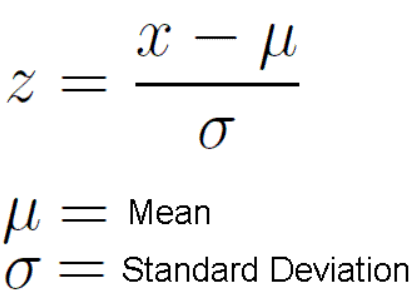
- Beta weighted more than std: at this stage, we are focusing on future-proofing our strategy against market downturns. We will focus more on std optimization in stages 4 and 5, on these forward-looking rankings of the stocks.
- Disproportionate penalties on stocks: The penalties are just arbitrarily large numbers to guarantee (most of the time) that a crashed or small-cap stock ranks way below the rest of the safer stocks, and will most likely be discluded from our ultimate portfolio. We only penalize the stocks, rather than dropping them from our list, in case future stages still need more stocks to meet minimum portfolio requirements (eg. 10 stock minimum), but these stay on only as a last resort.

#### Stage 4 - Stock selection algorithm

**What it does:** Starting from the lowest-risk stock, we repeatedly add the next stock that lowers std of the new combined portfolio the most. We start by only considering next stocks with a risk score below -0.5 (much safer than average). Only up to 4 stocks per sector may be chosen. If under these rules, fewer than 10 stocks are chosen, the risk score cutoff is loosened in steps of 0.1, to ensure penalized stocks are only a last resort, and safer stocks are considered first.

**Why these choices:**
- Choosing by portfolio std: std of a portfolio is not equal to the average of the stocks' individual std. It is actually less than this, which is the benefit of diversification, and this idea leads the whole picking process. The portfolio's volatility also depends on how stocks move together (eg. stock A zigs while stock B zags, because they are in contending industries). This effect can additionally lower portfolio std, and the picker captures these offsetting relationships that raw stat observations don't.
- Equal weighting combined portfolios: when judging stock picks, we compare the std of the combined equal-weighted portfolio chosen so far plus that candidate. As more stocks are added, the weight to each one in consideration decreases, and so at the beginning the picker favours stabler stocks, while later, it focuses more on how the stock behaves with the safer core other stocks (as described above). 
- # is there a formula for the above?
- Starting from lowest risk scored stock: as seen in class, adding a riskier stock to a stabler stock in a portfolio can raise the std of the overall portfolio, from the std of the stabler stock alone. To capture, and combat against this effect, we start off with a stock we consider very safe, and then build onto that portfolio with riskier stocks one at a time, each time choosing the next stock that keeps the portfolio's std lowest. Sometimes this increases or decreases the combined portfolio's std, which is compared to the previous safest alternative portfolio.
- Score cutoff of -0.5: Testing with the picker, we found that without a cutoff, it picks the riskiest stocks because they often offset the calmer ones. We still don't want to eagerly choose these risky stocks, so we restrict the picker to safer ones first, with safer ones still possibly offsetting each other. Gradually loosening it ensures at least 10 stocks are chosen.
- 4 stocks per sector: In the most restrictive case, we want at most 40% of 10 stocks in any sector. So this cap helps meet portfolio requirements (40% of 10 = 4). It also forces the portfolio to hold across industries and protect against sector-specific events/shocks (eg., regulation changes, outlook of an industry, etc.).  

#### Stage 5 - Weight optimization

**What it does:** Starting from equal weights, the optimizer tries moving 1% weight from one stock to another. It makes the shift if it lowers overall portfolio volatility, theoretically if it was held over a 1 year period in the past. It keeps on doing this until the weights minimize volatility, computing the optimal weights for that 1 year hold. Then, it shifts by 1 month, to consider a new 1 year period, and does the same thing. Throughout the process, each stock keeps at least 2% weight, no stock can exceed 15%, and no sector can exceed 40%. If the weight change makes the portfolio's annual return (average over our sample) less than inflation rate, it rejects that change. In the end, the average weights for each stock, as optimzied for every 1 year period, is computed, giving final weights.

**Why these choices:**
- Buy and hold: We emulate buying and holding portfolios in the past. Notably, this means weights of stocks would change in that portfolio as prices change. However, we want to consider this so that the weights chosen can... as time goes on, in a long-term future lens.
- Trying many 1-year periods: if we optimized for a single 1 year period, we would overfit to those events, and it would not reflect how the portfolio performs in the future, which has different events. Our strategy optimizes weights to work well across many different long-term periods.
- 2% minimum weight: Prevents weights that completely eradicate stocks, by giving meaningless weights near 0%, and overly relying on a few core stocks. Keeping some weighting in these stocks, rather than 0%, also helps maintain some diversification.
- Comparison to inflation rate: Client B wants to conserve as much money as possible, over a long period of time. If they just held completely unvolatile low growth stocks, which we try to achieve, they will still have a negative real rate of return, i.e. they lose money due to inflation over time. So if theoretically a portfolio with 0 volatility could be obtained, it still wouldn't help conserve the value of Client B's money, being as useless as cash at conserving it. So, we ensure that our weighted portfolio can beat inflation rate in our historical sample to increase the chance that it can do this in the future. In our tests we found that our portfolio anyways had really high nominal returns due to markets / large cap stocks performing well, so this may not make much of an impact. However, if a trul low volatility portfolio is achieved with new tickers, real returns should be kept positive.

- Comparison to equal weighted portfolio::::

**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.

- The past may not represent the future: all of our stats come from 1 period of past data, for simplification. For instance, the data does not include a full market crisis like 2008, which could be good for informing how this portfolio would perform in such a sever downturn, as our client wants a long-term portfolio and strategy. Our beta-based ranking can reduce this risk but cannot completely remove market risk.

- Concentration in sectors: Our portfolio in testing ended up with many stocks in consumer staples, healthcare, large banks, and telecom. These have historically been stable but share risks. #These stocks often pay dividends:? could that matter #hitting a sector here, ties to canadian economy, other markets, hit there very bad for portfolio

- Many of our holdings are US stocks, so their CAD value depends on the USD/CAD exchange rate. An increase in the Canadian dollar would lower the CAD value of these positions even if their US prices didn't change.

- Judgment: many parameters like the 0.3/0.7 weighting are judgment calls and not proven optimal values.

- Crash potential: a stock that has never crashed in the past still has the potential to do so in the future.

- Large cap volume: large-caps have higher volume and inherently more volatility on any trading day than a small-cap company does. While this increaes long-term / over-time stability, it may result in high short-term volatility, as shares trade hands more often.

- Equal weight selection: Our picker algorithm uses equal weights to decide stocks to combine into portfolio next. This may overlook stocks that can outperform others at a non-equal weight, or can deliver a better opposite directional benefit when weighted lower amount. But realistically, it would be really hard to implement dynamic weight considerations here, given portfolio restrctions and an unkown number of stocks we will have in the final portfolio.